<div align="center">

**DS201.R11.1 - Deep Learning trong Khoa học Dữ liệu**

**Báo cáo Lab 03:**

**MẠNG NEURAL HỒI QUY (RNN, LSTM, GRU VÀ BiLSTM)**

</div>

**Họ và tên:** Huỳnh Lâm Bảo Khang

**MSSV:** 24520738

**Lớp:** DS201.R11.1

**Bộ dữ liệu sử dụng:**
- **UIT-VSFC (Vietnamese Students' Feedback Corpus):** [Google Drive Link](https://drive.google.com/drive/folders/1rdcXNGt_3-QUvV8EtSvVsLMVeHmk6Yqk?usp=drive_link)

- **PhoNER_COVID19 (bản syllable):** [VinAI Research GitHub](https://github.com/VinAIResearch/PhoNER_COVID19)

---

#### Tổ chức mã nguồn
Có 4 module chính:

```text
Lab03/
├── data.py #Tải & kiểm chứng SHA-256 cho 6 tệp dữ liệu, xây vocab từ train, collate_cls/collate_ner, DataLoader seed=42
├── models.py #TextClassifier (RNN/LSTM/GRU + pack_padded_sequence), TokenTagger (BiLSTM + pad_packed_sequence), inspect_layers
├── engine.py #fit_tfidf_baseline, train/evaluate/fit_cls (dev macro-F1), train/evaluate/fit_ner (seqeval strict IOB2)
├── utils.py #set_seed, kiểm chứng bất biến padding (8 vs 64), vẽ biểu đồ Loss/F1/Confusion Matrix, phân tích lỗi dev
└── assignments.ipynb
```

#### Cấu hình chung của 4 bài

- **Cấu hình bắt buộc xuyên suốt:** emb_dim = 300 (học từ đầu, padding_idx = 0), hidden_size = 256 (mỗi chiều ở BiLSTM), dropout = 0.3, batch_size = 32, Adam(lr = 1e-3), clip_grad_norm_ = 1.0, tối đa 10 epoch, SEED = 42
- **Bài 1 - LSTM 5 lớp phân loại cảm xúc (UIT-VSFC):**
  - Kiến trúc: Embedding(1535, 300) -> LSTM(300, 256, num_layers=5) + packing -> Linear(256, 3) (3.138.007 tham số)
  - Yêu cầu thực nghiệm: Đối chiếu với baseline Majority & TF-IDF + Logistic Regression; chọn checkpoint theo dev macro-F1; báo cáo test metrics, Confusion Matrix và phân tích ít nhất 3 ca dự đoán sai trên tập dev
- **Bài 2 - GRU 5 lớp và so sánh có kiểm soát với LSTM (UIT-VSFC):**
  - Kiến trúc: Embedding(1535, 300) -> GRU(300, 256, num_layers=5) + packing -> Linear(256, 3) (2.468.823 tham số)
  - Yêu cầu thực nghiệm: Dùng đúng tập chia, từ điển và quy trình của Bài 1; lập bảng so sánh chất lượng macro-F1, số tham số và thời gian mỗi epoch
- **Bài 3 - Encoder BiLSTM 5 lớp cho nhận diện thực thể (PhoNER_COVID19):**
  - Kiến trúc: Embedding(2813, 300) -> BiLSTM(300, 256, num_layers=5) -> Linear(512, 21) (8.305.297 tham số)
  - Yêu cầu thực nghiệm: Dùng packing + CrossEntropyLoss(ignore_index=-100); chọn checkpoint theo dev entity micro-F1 (seqeval strict IOB2); phân tích ít nhất 3 kiểu lỗi trên dev và minh họa bằng ví dụ tự tạo
- **Bài 4\* - Ảnh hưởng của độ sâu num_layers $\in \{1, 2, 5\}$ trên LSTM (UIT-VSFC):**
  - Kiến trúc: So sánh LSTM với num_layers = 1 (1.032.663 tham số), num_layers = 2 (1.558.999 tham số) và num_layers = 5 (3.138.007 tham số, tái sử dụng từ Bài 1) ở cùng hidden_size = 256

> **Nguyên tắc chung:**
> 1. Từ điển (vocab, ner_vocab) và bộ TF-IDF chỉ được xây dựng từ tập train; từ ngoài tập từ điển ánh xạ về <unk> = 1
> 2. Dùng pack_padded_sequence để loại bỏ bước đệm khỏi phép hồi quy và chặn chuẩn gradient clip_grad_norm_(..., 1.0) trước optimizer.step()
> 3. Mọi quyết định chọn checkpoint best.pt đều dựa trên tập dev (macro-F1 cho phân loại cảm xúc, entity micro-F1 strict IOB2 cho NER); tập test chỉ được chấm một lần sau khi chốt mô hình

In [1]:
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys

#Tu dong cai seqeval
if importlib.util.find_spec("seqeval") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--use-pep517", "seqeval"], check=True)

#Tu dong clone repo tu GitHub neu mo notebook truc tiep tren Google Colab
REPO_URL = "https://github.com/khanghl/DS201-Lab03-RNN.git"
REPO_DIR = Path("/content/DS201-Lab03-RNN")

if "google.colab" in sys.modules and not Path("models.py").is_file():
    if not (REPO_DIR / "models.py").is_file():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    os.chdir(REPO_DIR)

#Tu dong nhan dien thu muc chua cac file .py
for candidate in [Path.cwd(), Path.cwd() / "Lab03", REPO_DIR]:
    if (candidate / "models.py").is_file():
        if str(candidate.resolve()) not in sys.path:
            sys.path.insert(0, str(candidate.resolve()))
        break

from seqeval.metrics import f1_score as seqeval_f1
from seqeval.scheme import IOB2
import torch
import torch.nn as nn

from data import (
    DATA_FILES,
    LABEL_TO_ID,
    PAD,
    PAD_TAG,
    SENTIMENT_LABELS,
    UNK,
    build_cls_loaders,
    build_ner_loaders,
    load_raw_datasets,
)
from engine import (
    evaluate_cls,
    evaluate_ner,
    fit_cls,
    fit_ner,
    fit_tfidf_baseline,
)
from models import TextClassifier, TokenTagger, n_params, n_trainable_params
from utils import (
    analyze_cls_dev_errors,
    analyze_ner_dev_errors,
    demo_synthetic_ner_examples,
    evaluate_cls_test,
    evaluate_ner_test,
    evaluate_tfidf_test,
    plot_cls_history,
    plot_cls_model_comparison,
    plot_cls_multi_curves,
    plot_dataset_overview,
    plot_ner_history,
    print_cls_comparison_table,
    print_final_submission_table,
    set_seed,
    verify_cls_packing,
    verify_ner_packing_and_loss,
)

#Cau hinh chung chuan theo bang thong so Lab 03
SEED = 42
EMB_DIM = 300
HIDDEN_SIZE = 256
NUM_LAYERS = 5
DROPOUT = 0.3
BATCH_SIZE = 32
LR = 1e-3
CLIP_NORM = 1.0
EPOCHS = 10

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results = {} #Luu ket qua danh gia cua toan bo thuc nghiem

print(f"Thu muc hien tai : {Path.cwd()}")
print(f"PyTorch          : {torch.__version__}")
print(f"Device           : {device}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else " (CPU)"))
print(
    f"Cau hinh chung   : SEED={SEED} | EMB={EMB_DIM} | HIDDEN={HIDDEN_SIZE} | "
    f"LAYERS={NUM_LAYERS} | DROPOUT={DROPOUT} | BATCH={BATCH_SIZE} | LR={LR} | EPOCHS={EPOCHS}"
)

Thu muc hien tai : /content/DS201-Lab03-RNN
PyTorch          : 2.14.1+cu130
Device           : cuda (Tesla T4)
Cau hinh chung   : SEED=42 | EMB=300 | HIDDEN=256 | LAYERS=5 | DROPOUT=0.3 | BATCH=32 | LR=0.001 | EPOCHS=10


#### Khảo sát dữ liệu, Xác thực SHA-256 & Chuẩn bị DataLoader

- Hàm load_raw_datasets("data") trong data.py tải trực tiếp 6 tệp dữ liệu từ nguồn gốc, kiểm tra mã băm SHA-256 và đối chiếu đúng kích thước chuẩn:
  - **UIT-VSFC:** 11.426 câu train, 1.583 câu dev, 3.166 câu test. Lớp neutral chỉ có 458 câu train (4.01%), gây mất cân bằng lớp rõ rệt nên độ đo chính bắt buộc là macro-F1 thay vì Accuracy
  - **PhoNER_COVID19 (syllable):** 5.027 câu train, 2.000 câu dev, 3.000 câu test (JSON Lines, giữ nguyên words và tags, không cắt ngắn câu để bảo toàn biên thực thể)
- Từ điển chỉ xây từ tập train (min_freq=2, <pad>=0, <unk>=1): thu được 1.535 token trên UIT-VSFC và 2.813 syllable cùng 21 nhãn BIO trên PhoNER

Da xac thuc SHA-256 cho 6/6 tep du lieu!
  train | UIT-VSFC: 11,426 cau | PhoNER syllable: 5,027 cau
  dev   | UIT-VSFC:  1,583 cau | PhoNER syllable: 2,000 cau
  test  | UIT-VSFC:  3,166 cau | PhoNER syllable: 3,000 cau

Phan bo nhan UIT-VSFC train : {'negative': 5325, 'neutral': 458, 'positive': 5643} (neutral chiem 4.01%)
Tu dien UIT-VSFC (train)    : 1,535 token (<pad>=0, <unk>=1)
Tu dien PhoNER (train)      : 2,813 syllable | So nhan BIO: 21 (PAD_TAG=-100)


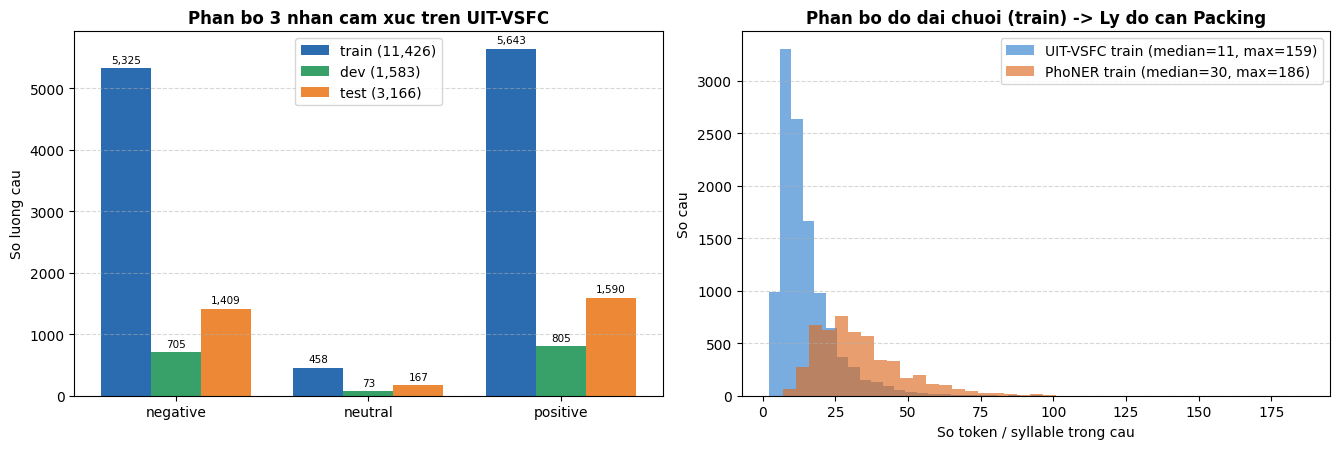

In [2]:
vsfc, ner = load_raw_datasets("data")

train_dl, dev_dl, test_dl, vocab = build_cls_loaders(
    vsfc, batch_size=BATCH_SIZE, min_freq=2, seed=SEED
)
ner_train_dl, ner_dev_dl, ner_test_dl, ner_vocab, TAGS, tag_to_id = build_ner_loaders(
    ner, batch_size=BATCH_SIZE, min_freq=2, seed=SEED
)

print("Da xac thuc SHA-256 cho 6/6 tep du lieu!")
for split in ("train", "dev", "test"):
    print(f"  {split:<5} | UIT-VSFC: {len(vsfc[split]):>6,} cau | PhoNER syllable: {len(ner[split]):>5,} cau")

vsfc_train_cnt = {lb: sum(r["sentiment"] == lb for r in vsfc["train"]) for lb in SENTIMENT_LABELS}
print(f"\nPhan bo nhan UIT-VSFC train : {vsfc_train_cnt} (neutral chiem {vsfc_train_cnt['neutral'] / len(vsfc['train']) * 100:.2f}%)")
print(f"Tu dien UIT-VSFC (train)    : {len(vocab):,} token (<pad>={vocab['<pad>']}, <unk>={vocab['<unk>']})")
print(f"Tu dien PhoNER (train)      : {len(ner_vocab):,} syllable | So nhan BIO: {len(TAGS)} (PAD_TAG={PAD_TAG})")

plot_dataset_overview(vsfc, ner, save_path="outputs/dataset_overview.png")

---
### Bài 1: LSTM 5 lớp cho phân loại cảm xúc trên UIT-VSFC

#### Kiến trúc và bảng tính tham số lý thuyết (emb=300, hidden=256, num_layers=5)

Trong PyTorch, mỗi tầng nn.LSTM một chiều có 4 cổng (input, forget, cell, output), mỗi cổng gồm ma trận trọng số đầu vào $W_{ih} \in \mathbb{R}^{H \times d_{\text{in}}}$, trọng số hồi quy $W_{hh} \in \mathbb{R}^{H \times H}$ và hai vector độ chệch $b_{ih}, b_{hh} \in \mathbb{R}^{H}$, tổng cộng $4H(d_{\text{in}} + H + 2)$ tham số:

| Thành phần | Cấu hình chi tiết | Output shape | Công thức tính tham số | Số tham số |
| :--- | :--- | :---: | :--- | ---: |
| **Embedding** | Embedding(1535, 300, padding_idx=0) | [B, L, 300] | $1,535 \times 300$ | 460,500 |
| **LSTM layer 1** | $d_{\text{in}} = 300 \rightarrow H = 256$ | [B, L, 256] | $4 \times 256 \times (300 + 256 + 2)$ | 571,392 |
| **LSTM layers 2–5** | 4 tầng tiếp theo ($d_{\text{in}} = 256 \rightarrow H = 256$, dropout=0.3) | h_n[-1]: [B, 256] | $4 \times [4 \times 256 \times (256 + 256 + 2)]$ | 2,105,344 |
| **Dropout + FC** | Dropout(0.3) $\rightarrow$ Linear(256, 3) *(logits thô)* | [B, 3] | $256 \times 3 + 3$ | 771 |
| **TỔNG** | **Embedding + 5 tầng LSTM + Linear** | **3 logits** | $460,500 + 571,392 + 2,105,344 + 771$ | **3,138,007** |

Tang             |    Ly thuyet |      Thuc te | Doi chieu 
----------------------------------------------------------
Embedding        |      460,500 |      460,500 |    Khop   
LSTM layer 1     |      571,392 |      571,392 |    Khop   
LSTM layer 2     |      526,336 |      526,336 |    Khop   
LSTM layer 3     |      526,336 |      526,336 |    Khop   
LSTM layer 4     |      526,336 |      526,336 |    Khop   
LSTM layer 5     |      526,336 |      526,336 |    Khop   
Linear (fc)      |          771 |          771 |    Khop   
----------------------------------------------------------
Tong cong        |    3,138,007 |    3,138,007 |    Khop   

Kiem tra packing (dem 8 vs 64 vi tri): PASS (sai khac neu khong packing = 0.002775)

KET QUA BASELINE TF-IDF + LOGISTIC REGRESSION (UIT-VSFC TEST):
    - Cau hinh          : TF-IDF(1-2g, 13,308 feat) + LogReg(39,927 w)
    - Thoi gian fit     : 3.48s (Majority dev macro-F1 = 0.2247)
    - Dev macro-F1      : 0.6894
    - Test Accuracy     

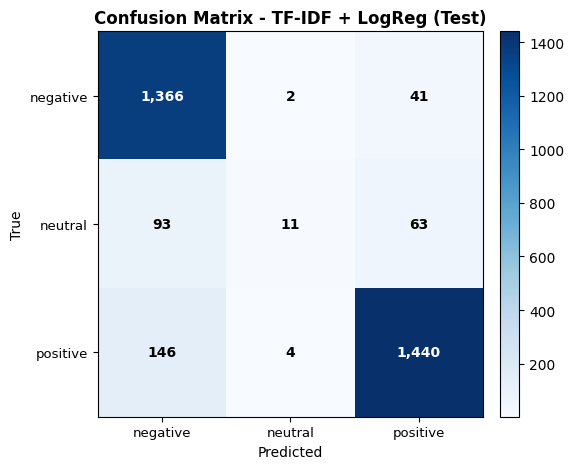

In [3]:
#Kiem tra tham so tung tang cua LSTM 5 lop, kiem chung packing (dem 8 vs 64) va chay Baseline TF-IDF
set_seed(SEED)
lstm_probe = TextClassifier(
    vocab_size=len(vocab), kind="LSTM", emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT,
).to(device)

print(f"{'Tang':<16} | {'Ly thuyet':>12} | {'Thuc te':>12} | {'Doi chieu':^10}")
print("-" * 58)
for name, exp_p, act_p in lstm_probe.inspect_layers():
    assert exp_p == act_p
    print(f"{name:<16} | {exp_p:>12,} | {act_p:>12,} | {'Khop':^10}")
print("-" * 58)
print(f"{'Tong cong':<16} | {3_138_007:>12,} | {n_params(lstm_probe):>12,} | {'Khop':^10}")
assert n_params(lstm_probe) == 3_138_007

unpacked_diff = verify_cls_packing(lstm_probe, vocab, device)
print(f"\nKiem tra packing (dem 8 vs 64 vi tri): PASS (sai khac neu khong packing = {unpacked_diff:.6f})\n")
del lstm_probe

#Chay Baseline Majority & TF-IDF + LogisticRegression tren cung bo chia train/dev/test
tfidf_pipe, tfidf_summary = fit_tfidf_baseline(vsfc["train"], vsfc["dev"], LABEL_TO_ID)
results["tfidf"] = evaluate_tfidf_test(
    tfidf_pipe, vsfc["test"], LABEL_TO_ID, SENTIMENT_LABELS,
    summary=tfidf_summary, out_dir="outputs/baseline_tfidf",
)

Bai 1 - Huan luyen LSTM 5 lop tren UIT-VSFC (chon checkpoint theo dev macro-F1)
epoch  1/10  train 0.4237/0.8451   dev 0.3584/0.8983  macro-F1 0.6905   (7.28s)  *
epoch  2/10  train 0.2725/0.9123   dev 0.2788/0.9141  macro-F1 0.7331   (5.61s)  *
epoch  3/10  train 0.2307/0.9281   dev 0.2684/0.9135  macro-F1 0.7388   (6.13s)  *
epoch  4/10  train 0.1915/0.9423   dev 0.2639/0.9223  macro-F1 0.7789   (5.99s)  *
epoch  5/10  train 0.1672/0.9513   dev 0.2785/0.9210  macro-F1 0.7729   (5.98s)
epoch  6/10  train 0.1390/0.9617   dev 0.2658/0.9229  macro-F1 0.7961   (6.04s)  *
epoch  7/10  train 0.1199/0.9684   dev 0.3283/0.9179  macro-F1 0.7747   (5.67s)
epoch  8/10  train 0.1013/0.9737   dev 0.3089/0.9236  macro-F1 0.8036   (6.33s)  *
epoch  9/10  train 0.0909/0.9777   dev 0.3669/0.9179  macro-F1 0.7809   (5.59s)
epoch 10/10  train 0.0805/0.9809   dev 0.3567/0.9154  macro-F1 0.7918   (6.33s)
-> best dev macro-F1: 0.8036 (epoch 8) | trung binh: 6.10s/epoch | da luu: outputs/bai1_lstm5/best.pt


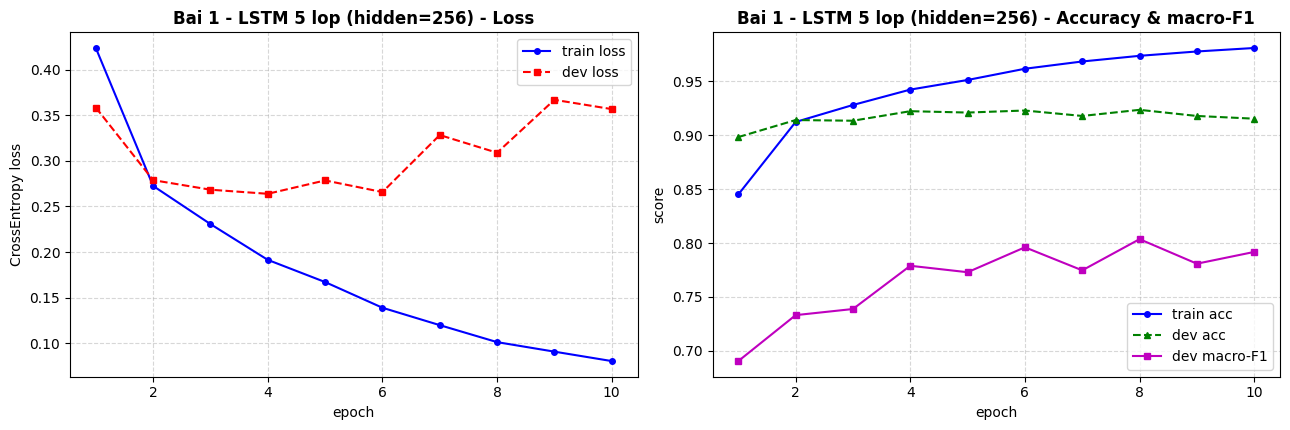

KET QUA TAP TEST - LSTM 5 lop (hidden=256):
    - Tong so tham so   : 3,138,007 (cap nhat: 3,138,007)
    - Checkpoint dev    : epoch 8 (dev macro-F1 = 0.8036)
    - Thoi gian / epoch : 6.10s
    - Test Loss         : 0.4063
    - Accuracy          : 0.8999 (89.99%)
    - Precision (macro) : 0.7974
    - Recall (macro)    : 0.7522
    - macro-F1 (chinh)  : 0.7700

Bang Precision, Recall, F1 tung lop tren tap Test UIT-VSFC:
              precision    recall  f1-score   support

    negative     0.9010    0.9297    0.9151      1409
     neutral     0.5678    0.4012    0.4702       167
    positive     0.9235    0.9258    0.9246      1590

    accuracy                         0.8999      3166
   macro avg     0.7974    0.7522    0.7700      3166
weighted avg     0.8947    0.8999    0.8964      3166



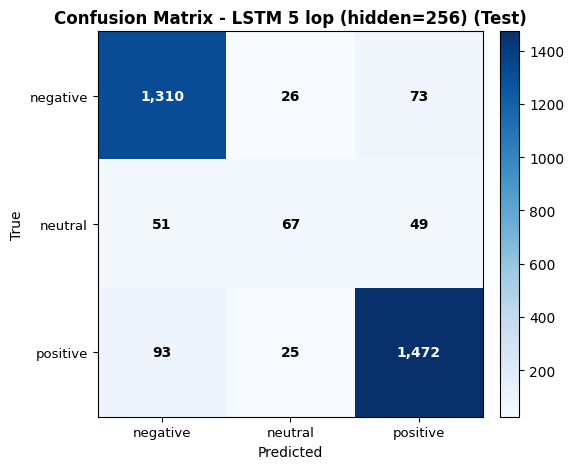

Tong so cau du doan sai tren dev: 121/1583 (7.64%)
Phan bo cac cap nhan bi nham tren dev (Nhan that -> Du doan):
    - positive   -> negative   :  34 cau
    - negative   -> positive   :  25 cau
    - neutral    -> negative   :  19 cau
    - neutral    -> positive   :  19 cau
    - negative   -> neutral    :  16 cau
    - positive   -> neutral    :   8 cau

Chi tiet 5 truong hop du doan sai tieu bieu tren tap dev:
  [1] dev#939 | That: negative (p=0.001) -> Du doan: positive (conf=0.999)
      Cau: "cô dạy rất nhiệt tình , tận tâm và chu đáo ."
  [2] dev#117 | That: neutral (p=0.001) -> Du doan: positive (conf=0.998)
      Cau: "sự nhiệt tình ."
  [3] dev#489 | That: neutral (p=0.004) -> Du doan: negative (conf=0.991)
      Cau: "đôi lúc thầy " chia sẻ " hơi nhiều thời gian và việc học vào chương trình thì bị bớt lại nhưng điều này cũng không mấy ảnh hưởng gì ."
  [4] dev#378 | That: positive (p=0.005) -> Du doan: negative (conf=0.991)
      Cau: "đôi khi thầy có đến trễ một chút nhưng

In [4]:
#Bai 1: Huan luyen mang LSTM 5 lop (hidden_size=256, emb=300, Adam lr=1e-3, clip_grad=1.0)
set_seed(SEED)
lstm_5 = TextClassifier(
    vocab_size=len(vocab),
    kind="LSTM",
    emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
)

print("Bai 1 - Huan luyen LSTM 5 lop tren UIT-VSFC (chon checkpoint theo dev macro-F1)")
hist_lstm5, info_lstm5 = fit_cls(
    model=lstm_5,
    train_dl=train_dl,
    dev_dl=dev_dl,
    epochs=EPOCHS,
    lr=LR,
    device=device,
    out_dir="outputs/bai1_lstm5",
    classes=SENTIMENT_LABELS,
    max_norm=CLIP_NORM,
    seed=SEED,
)

plot_cls_history(
    hist_lstm5,
    title="Bai 1 - LSTM 5 lop (hidden=256)",
    save_path="outputs/bai1_lstm5/loss_curve.png",
)

results["lstm_5"] = evaluate_cls_test(
    model=lstm_5,
    test_dl=test_dl,
    labels=SENTIMENT_LABELS,
    device=device,
    model_name="LSTM 5 lop (hidden=256)",
    summary=info_lstm5,
    out_dir="outputs/bai1_lstm5",
)

#Phan tich cac truong hop du doan sai tieu bieu tren tap dev (khong dung tap test de phan tich loi)
dev_errors_lstm5 = analyze_cls_dev_errors(
    model=lstm_5,
    dev_dl=dev_dl,
    vsfc_dev=vsfc["dev"],
    labels=SENTIMENT_LABELS,
    device=device,
    max_cases=5,
)

#### Nhận xét Bài 1

- **Vai trò của pack_padded_sequence và chặn chuẩn gradient:**
  - padding_idx=0 chỉ giữ vector nhúng của <pad> bằng $\mathbf{0}$, nhưng độ chệch $b_{hh}, b_{ih} \neq \mathbf{0}$ vẫn làm trạng thái ẩn $h_t$ biến đổi nếu chạy hồi quy qua các bước đệm. Nhờ pack_padded_sequence, trạng thái cuối h_n[-1] lấy đúng tại từ thật cuối cùng của mỗi câu, bất biến với chiều dài đệm trong batch
  - Với 5 tầng LSTM xếp chồng, tích chuỗi Jacobian theo cả chiều thời gian lẫn chiều sâu dễ gây bùng nổ chuẩn gradient ở những câu dài; clip_grad_norm_(..., 1.0) giữ bước cập nhật Adam ổn định
- **So sánh với Baseline TF-IDF + Logistic Regression:**
  - TF-IDF (1–2 gram) rất mạnh trên các cụm từ khen/chê tường minh nhưng đối xử cực kỳ bất lợi với lớp thiểu số neutral (do chuẩn hóa L2 kết hợp điều chuẩn của Logistic Regression ưu tiên hai lớp đa số positive và negative, khiến Recall lớp neutral trên test chỉ đạt 6.59%, F1 lớp neutral đạt 0.1196)
  - LSTM 5 lớp nắm bắt thứ tự từ và quan hệ phủ định/chuyển ý ("không quá khó", "nhiệt tình nhưng..."), cải thiện đáng kể khả năng nhận diện lớp neutral và từ đó nâng cao độ đo chính macro-F1
- **Ba nhóm lỗi dự đoán sai đặc trưng trên tập dev:**
  1. **Câu phản hồi ghép hai vế khen – chê trái chiều** (có liên từ *"nhưng"*, *"tuy nhiên"*, *"còn"*): Một vế mang sắc thái tích cực, vế sau góp ý hạn chế khiến ranh giới giữa neutral, negative và positive ngay cả với người gán nhãn cũng rất sát nhau
  2. **Nhầm lẫn lớp thiểu số neutral sang negative hoặc positive:** Vì neutral chỉ chiếm 4.01% tập train (458 câu), các câu mang tính mô tả khách quan hoặc đề xuất trung tính không chứa từ khóa cảm xúc mạnh dễ bị kéo về hai lớp lớn
  3. **Câu ngắn chứa từ hiếm (<unk>) hoặc hàm ý gián tiếp:** Khi từ khóa quyết định sắc thái xuất hiện dưới 2 lần trong train (bị ánh xạ thành <unk>) hoặc câu khen/chê bằng ngữ điệu gián tiếp, trạng thái ẩn cuối dễ nghiêng sai lớp

---
### Bài 2: GRU 5 lớp và so sánh có kiểm soát với LSTM trên UIT-VSFC

#### Kiến trúc GRU 5 lớp và đối chiếu tham số với LSTM (hidden=256, num_layers=5)

Khác với LSTM dùng 4 cổng và tách riêng trạng thái ô nhớ $c_t$ với trạng thái ẩn $h_t$, **GRU (Gated Recurrent Unit)** gộp thành **3 cổng** (reset, update, new) và truyền trực tiếp duy nhất h_n mà không cần $c_n$. Vì vậy số tham số của mỗi tầng hồi quy GRU bằng đúng **$3/4$ (75%)** của tầng LSTM tương ứng:

| Thành phần | Cấu hình chi tiết | Công thức tính tham số | GRU 5 lớp | LSTM 5 lớp (Bài 1) |
| :--- | :--- | :--- | ---: | ---: |
| **Embedding** | Embedding(1535, 300, padding_idx=0) | $1,535 \times 300$ | 460,500 | 460,500 |
| **Tầng hồi quy 1** | $d_{\text{in}} = 300 \rightarrow H = 256$ | $3 \times 256 \times (300 + 256 + 2)$ | 428,544 | 571,392 |
| **Tầng hồi quy 2–5** | 4 tầng ($d_{\text{in}} = 256 \rightarrow H = 256$, dropout=0.3) | $4 \times [3 \times 256 \times (256 + 256 + 2)]$ | 1,579,008 | 2,105,344 |
| **Linear (fc)** | Linear(256, 3) | $256 \times 3 + 3$ | 771 | 771 |
| **TỔNG** | **Cùng dữ liệu, từ điển và siêu tham số** | Giảm **669,184** tham số (**-21.33%**) | **2,468,823** | **3,138,007** |

In [5]:
#Doi chieu tham so ly thuyet va thuc te cua GRU 5 lop so voi LSTM 5 lop
gru_probe = TextClassifier(
    vocab_size=len(vocab), kind="GRU", emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT,
)
lstm_ref = TextClassifier(
    vocab_size=len(vocab), kind="LSTM", emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT,
)

for name, exp_p, act_p in gru_probe.inspect_layers():
    assert exp_p == act_p
    print(f"  {name:<16} : {act_p:>10,} tham so")

assert n_params(gru_probe) == 2_468_823
assert n_params(gru_probe.rnn) * 4 == n_params(lstm_ref.rnn) * 3
print(f"\nTong tham so GRU 5 lop  : {n_params(gru_probe):,}")
print(f"Khoi hoi quy GRU / LSTM : {n_params(gru_probe.rnn):,} / {n_params(lstm_ref.rnn):,} = {n_params(gru_probe.rnn)/n_params(lstm_ref.rnn):.2%} (dung bang 3/4)")
del gru_probe, lstm_ref

  Embedding        :    460,500 tham so
  GRU layer 1      :    428,544 tham so
  GRU layer 2      :    394,752 tham so
  GRU layer 3      :    394,752 tham so
  GRU layer 4      :    394,752 tham so
  GRU layer 5      :    394,752 tham so
  Linear (fc)      :        771 tham so

Tong tham so GRU 5 lop  : 2,468,823
Khoi hoi quy GRU / LSTM : 2,007,552 / 2,676,736 = 75.00% (dung bang 3/4)


Bai 2 - Huan luyen GRU 5 lop tren UIT-VSFC (cung cau hinh voi Bai 1)
epoch  1/10  train 0.3845/0.8632   dev 0.2984/0.9015  macro-F1 0.7179   (5.52s)  *
epoch  2/10  train 0.2618/0.9169   dev 0.2998/0.9033  macro-F1 0.7640   (5.86s)  *
epoch  3/10  train 0.2169/0.9330   dev 0.2409/0.9248  macro-F1 0.7913   (5.23s)  *
epoch  4/10  train 0.1831/0.9461   dev 0.2586/0.9248  macro-F1 0.7991   (5.99s)  *
epoch  5/10  train 0.1534/0.9559   dev 0.3192/0.9242  macro-F1 0.7732   (5.28s)
epoch  6/10  train 0.1282/0.9661   dev 0.3133/0.9204  macro-F1 0.7704   (6.18s)
epoch  7/10  train 0.1117/0.9696   dev 0.3405/0.9160  macro-F1 0.7790   (5.14s)
epoch  8/10  train 0.0963/0.9740   dev 0.3327/0.9210  macro-F1 0.8014   (5.96s)  *
epoch  9/10  train 0.0783/0.9804   dev 0.3717/0.9147  macro-F1 0.7829   (5.25s)
epoch 10/10  train 0.0693/0.9827   dev 0.3774/0.9166  macro-F1 0.7809   (5.40s)
-> best dev macro-F1: 0.8014 (epoch 8) | trung binh: 5.58s/epoch | da luu: outputs/bai2_gru5/best.pt



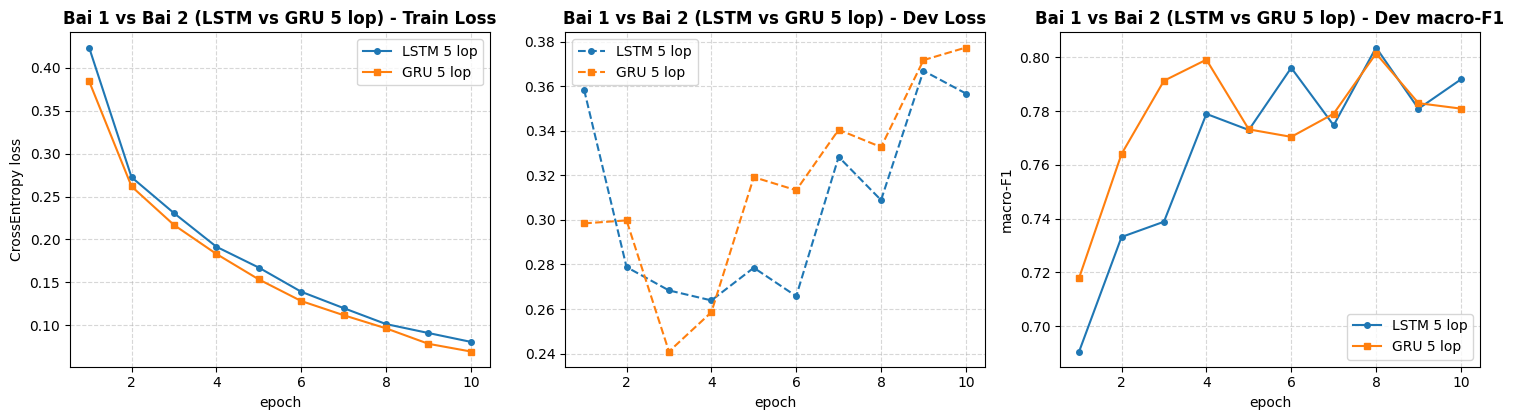

KET QUA TAP TEST - GRU 5 lop (hidden=256):
    - Tong so tham so   : 2,468,823 (cap nhat: 2,468,823)
    - Checkpoint dev    : epoch 8 (dev macro-F1 = 0.8014)
    - Thoi gian / epoch : 5.58s
    - Test Loss         : 0.4021
    - Accuracy          : 0.9021 (90.21%)
    - Precision (macro) : 0.7699
    - Recall (macro)    : 0.7486
    - macro-F1 (chinh)  : 0.7578

Bang Precision, Recall, F1 tung lop tren tap Test UIT-VSFC:
              precision    recall  f1-score   support

    negative     0.9109    0.9354    0.9230      1409
     neutral     0.4672    0.3832    0.4211       167
    positive     0.9317    0.9270    0.9294      1590

    accuracy                         0.9021      3166
   macro avg     0.7699    0.7486    0.7578      3166
weighted avg     0.8979    0.9021    0.8997      3166



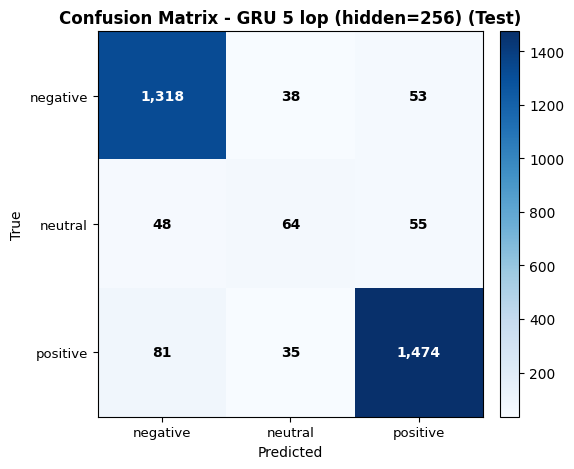

=== So sanh Bai 1 & Bai 2: Baseline TF-IDF vs LSTM 5 lop vs GRU 5 lop ===
Mo hinh                        |      Tham so | Best Ep |      s/ep |   Dev F1 | Test Acc |   Test P |   Test R |  Test F1
--------------------------------------------------------------------------------------------------------------------------
TF-IDF + Logistic Regression   |       39,927 |    —    | 3.48s (fit) |   0.6894 |   0.8898 |   0.8103 |   0.6470 |   0.6483
LSTM 5 lop (hidden=256)        |    3,138,007 |    8    |     6.10s |   0.8036 |   0.8999 |   0.7974 |   0.7522 |   0.7700
GRU 5 lop (hidden=256)         |    2,468,823 |    8    |     5.58s |   0.8014 |   0.9021 |   0.7699 |   0.7486 |   0.7578



In [6]:
#Bai 2: Khoi tao lai seed va huan luyen GRU 5 lop doc lap tren cung bo chia & tu dien cua Bai 1
set_seed(SEED)
gru_5 = TextClassifier(
    vocab_size=len(vocab),
    kind="GRU",
    emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
)

print("Bai 2 - Huan luyen GRU 5 lop tren UIT-VSFC (cung cau hinh voi Bai 1)")
hist_gru5, info_gru5 = fit_cls(
    model=gru_5,
    train_dl=train_dl,
    dev_dl=dev_dl,
    epochs=EPOCHS,
    lr=LR,
    device=device,
    out_dir="outputs/bai2_gru5",
    classes=SENTIMENT_LABELS,
    max_norm=CLIP_NORM,
    seed=SEED,
)

plot_cls_multi_curves(
    [("LSTM 5 lop", hist_lstm5), ("GRU 5 lop", hist_gru5)],
    title="Bai 1 vs Bai 2 (LSTM vs GRU 5 lop)",
    save_path="outputs/bai2_gru5/lstm_vs_gru_curves.png",
)

results["gru_5"] = evaluate_cls_test(
    model=gru_5,
    test_dl=test_dl,
    labels=SENTIMENT_LABELS,
    device=device,
    model_name="GRU 5 lop (hidden=256)",
    summary=info_gru5,
    out_dir="outputs/bai2_gru5",
)

#Bang so sanh co kiem soat giua Baseline TF-IDF, LSTM 5 lop va GRU 5 lop
b12_records = [results[k] for k in ("tfidf", "lstm_5", "gru_5") if k in results]
print_cls_comparison_table(
    b12_records,
    title="So sanh Bai 1 & Bai 2: Baseline TF-IDF vs LSTM 5 lop vs GRU 5 lop",
)

#### Nhận xét Bài 2 & So sánh chất lượng – chi phí giữa GRU và LSTM

- **Chi phí tham số và tốc độ thực thi:**
  - Nhờ loại bỏ cổng output riêng biệt và đường truyền trạng thái ô nhớ $c_t$, GRU 5 lớp giảm 669.184 tham số (từ 3.138.007 xuống 2.468.823 và giảm 25% số phép nhân ma trận trong các tầng hồi quy). Vì vậy thời gian trung bình mỗi epoch của GRU thấp hơn so với LSTM trên cùng kích thước batch
- **Động học hội tụ và chất lượng phân loại (macro-F1):**
  - Phản hồi sinh viên trong UIT-VSFC có độ dài trung bình khá ngắn (trung vị chỉ khoảng 11–12 âm tiết/từ). Trên chuỗi ngắn – trung bình và mạng sâu 5 tầng, cổng cập nhật $z_t$ tuyến tính trực tiếp trên $h_t$ của GRU thường giúp tín hiệu đạo hàm truyền qua 5 tầng nhanh ngay từ những epoch đầu, trong khi LSTM cần thêm vài epoch để ổn định đồng thời cả cổng quên $f_t$ lẫn cổng xuất $o_t$
  - Cả hai kiến trúc đều đạt hiệu năng cạnh tranh sát nhau trên tập test, minh chứng rằng với bài toán phân loại cảm xúc câu ngắn tiếng Việt, GRU mang lại tỉ số chất lượng / chi phí tính toán rất hiệu quả

---
### Bài 3: Encoder BiLSTM 5 lớp cho nhận diện thực thể (NER) trên PhoNER_COVID19

#### Kiến trúc TokenTagger (5 lớp BiLSTM, hidden_size=256 mỗi chiều + Linear(512, 21))

Đối với bài toán gán nhãn chuỗi BIO, việc quyết định biên thực thể tại vị trí $t$ phụ thuộc vào cả ngữ cảnh phía trước lẫn phía sau (ví dụ chữ "Chợ" đi trước "Rẫy" là ORGANIZATION, đi trước "Bến Thành" là LOCATION). Do đó Encoder dùng **BiLSTM 5 lớp**:
- Ở tầng 1, chiều xuôi và chiều ngược đều nhận vector nhúng $d_{\text{in}} = 300$, xuất ra $2 \times 256 = 512$ chiều
- Từ tầng 2 đến tầng 5, mỗi chiều nhận đầu vào nối ghép $d_{\text{in}} = 2H = 512$ từ tầng dưới
- pad_packed_sequence(..., total_length=ids.size(1)) khôi phục đúng chiều dài padded của batch để ghép cặp với nhãn đệm PAD_TAG = -100 trong CrossEntropyLoss(ignore_index=-100)
- Đánh giá bắt buộc bằng **seqeval chế độ strict theo chuẩn IOB2 (entity micro-F1)**: một thực thể chỉ được tính là đúng khi khớp đồng thời **điểm đầu, điểm cuối và loại thực thể** (không dùng token accuracy vì phần lớn token là nhãn "O")

| Thành phần | Cấu hình chi tiết | Output shape | Công thức tính tham số | Số tham số |
| :--- | :--- | :---: | :--- | ---: |
| **Embedding** | Embedding(2813, 300, padding_idx=0) | [B, L, 300] | $2,813 \times 300$ | 843,900 |
| **BiLSTM layer 1** | 2 chiều $\times$ ($300 \rightarrow 256$) | [B, L, 512] | $2 \times 4 \times 256 \times (300 + 256 + 2)$ | 1,142,784 |
| **BiLSTM layers 2–5** | 4 tầng $\times$ 2 chiều $\times$ ($512 \rightarrow 256$) | [B, L, 512] | $4 \times [2 \times 4 \times 256 \times (512 + 256 + 2)]$ | 6,307,840 |
| **Dropout + FC** | Dropout(0.3) $\rightarrow$ Linear(512, 21) | [B, L, 21] | $512 \times 21 + 21$ | 10,773 |
| **TỔNG** | **Encoder BiLSTM 5 lớp + Linear** | **21 BIO logits/token** | $843,900 + 1,142,784 + 6,307,840 + 10,773$ | **8,305,297** |

In [7]:
#Minh hoa su khac biet giua Token Accuracy va Strict Entity F1 + Kiem tra tham so & padding BiLSTM
gold_demo = [["O", "B-LOCATION", "I-LOCATION", "O"]]
pred_demo = [["O", "B-LOCATION", "O", "O"]]
tok_acc_demo = sum(a == b for a, b in zip(gold_demo[0], pred_demo[0])) / len(gold_demo[0])
ent_f1_demo = seqeval_f1(gold_demo, pred_demo, mode="strict", scheme=IOB2)
print(f"Vi du minh hoa: Token accuracy = {tok_acc_demo:.2f} (dung 3/4 token) nhung Strict Entity F1 = {ent_f1_demo:.2f} (sai bien thuc the)\n")

set_seed(SEED)
ner_probe = TokenTagger(
    vocab_size=len(ner_vocab), num_tags=len(TAGS),
    emb_dim=EMB_DIM, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT,
).to(device)

print(f"{'Tang':<18} | {'Ly thuyet':>12} | {'Thuc te':>12} | {'Doi chieu':^10}")
print("-" * 60)
for name, exp_p, act_p in ner_probe.inspect_layers():
    assert exp_p == act_p
    print(f"{name:<18} | {exp_p:>12,} | {act_p:>12,} | {'Khop':^10}")
print("-" * 60)
print(f"{'Tong cong':<18} | {8_305_297:>12,} | {n_params(ner_probe):>12,} | {'Khop':^10}")
assert n_params(ner_probe) == 8_305_297

verify_ner_packing_and_loss(ner_probe, ner_vocab, tag_to_id, len(TAGS), device, pad_tag=PAD_TAG)
print("\nKiem tra BiLSTM dem 8/64 & CrossEntropyLoss(ignore_index=-100): PASS")
del ner_probe

Vi du minh hoa: Token accuracy = 0.75 (dung 3/4 token) nhung Strict Entity F1 = 0.00 (sai bien thuc the)

Tang               |    Ly thuyet |      Thuc te | Doi chieu 
------------------------------------------------------------
Embedding          |      843,900 |      843,900 |    Khop   
BiLSTM layer 1     |    1,142,784 |    1,142,784 |    Khop   
BiLSTM layer 2     |    1,576,960 |    1,576,960 |    Khop   
BiLSTM layer 3     |    1,576,960 |    1,576,960 |    Khop   
BiLSTM layer 4     |    1,576,960 |    1,576,960 |    Khop   
BiLSTM layer 5     |    1,576,960 |    1,576,960 |    Khop   
Linear (512->21)   |       10,773 |       10,773 |    Khop   
------------------------------------------------------------
Tong cong          |    8,305,297 |    8,305,297 |    Khop   

Kiem tra BiLSTM dem 8/64 & CrossEntropyLoss(ignore_index=-100): PASS


Bai 3 - Huan luyen BiLSTM 5 lop cho PhoNER syllable (seqeval strict IOB2)
epoch  1/10  train_loss 0.6932   dev_loss 0.3305  entity-F1 0.6795 (P=0.7037, R=0.6570)   (8.32s)  *
epoch  2/10  train_loss 0.1588   dev_loss 0.1853  entity-F1 0.8336 (P=0.8509, R=0.8171)   (9.33s)  *
epoch  3/10  train_loss 0.0859   dev_loss 0.1507  entity-F1 0.8752 (P=0.8870, R=0.8637)   (8.95s)  *
epoch  4/10  train_loss 0.0627   dev_loss 0.1854  entity-F1 0.8683 (P=0.8748, R=0.8619)   (8.45s)
epoch  5/10  train_loss 0.0471   dev_loss 0.1448  entity-F1 0.8895 (P=0.8914, R=0.8877)   (8.85s)  *
epoch  6/10  train_loss 0.0377   dev_loss 0.1487  entity-F1 0.9004 (P=0.9095, R=0.8914)   (9.03s)  *
epoch  7/10  train_loss 0.0266   dev_loss 0.1856  entity-F1 0.8947 (P=0.9169, R=0.8736)   (9.47s)
epoch  8/10  train_loss 0.0228   dev_loss 0.1692  entity-F1 0.9010 (P=0.9100, R=0.8922)   (8.34s)  *
epoch  9/10  train_loss 0.0185   dev_loss 0.2019  entity-F1 0.9000 (P=0.9142, R=0.8862)   (9.07s)
epoch 10/10  train_loss 0.

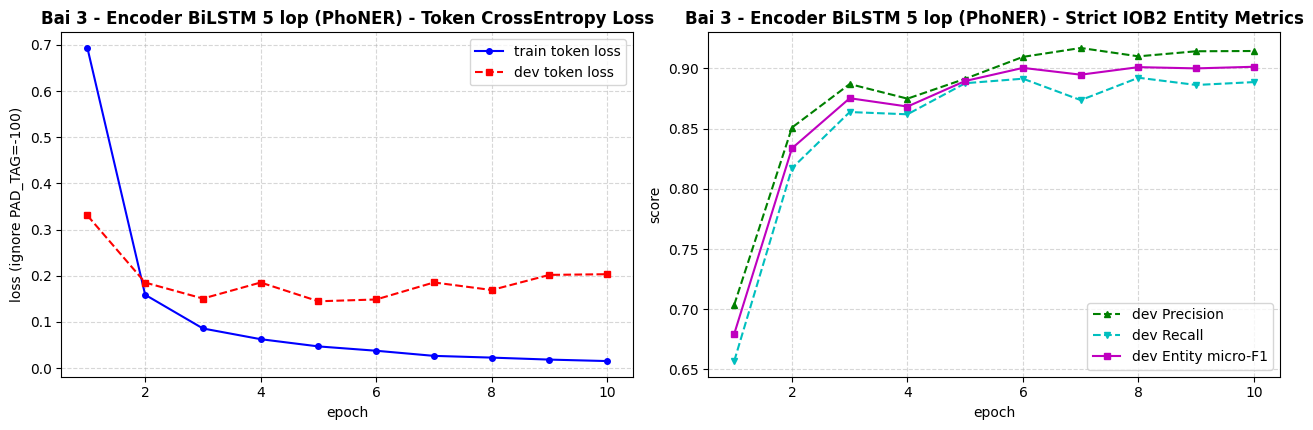

KET QUA TAP TEST - BiLSTM NER 5 lop (PhoNER syllable):
    - Tong so tham so       : 8,305,297 (cap nhat: 8,305,297)
    - Checkpoint dev        : epoch 10 (dev entity-F1 = 0.9013)
    - Thoi gian / epoch     : 8.88s
    - Test Token Loss       : 0.2447
    - Entity Precision      : 0.9105
    - Entity Recall         : 0.8793
    - Entity micro-F1 (IOB2): 0.8947

Bang Precision, Recall, F1 tung loai thuc the (seqeval strict IOB2):
                     precision    recall  f1-score   support

                AGE     0.9687    0.9038    0.9351       582
               DATE     0.9779    0.9637    0.9708      1654
             GENDER     0.9566    0.9069    0.9311       462
                JOB     0.6545    0.4162    0.5088       173
           LOCATION     0.9127    0.8969    0.9047      4441
               NAME     0.8106    0.5786    0.6752       318
       ORGANIZATION     0.8213    0.7691    0.7944       771
         PATIENT_ID     0.9410    0.9631    0.9519      2005
SYMPTOM_AND_DIS

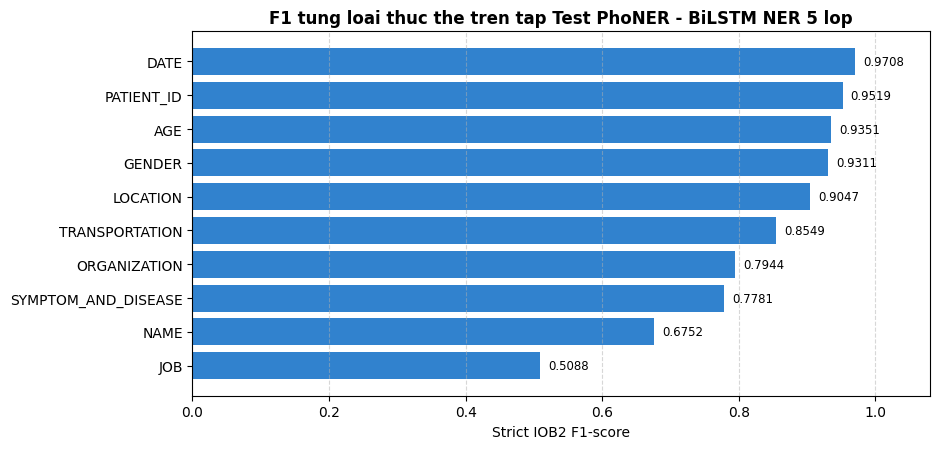

PHAN TICH DINH LUONG CAC KIEU LOI TREN TAP DEV PHONER (STRICT IOB2):
    - Tong thuc the that tren dev           : 7,478 (khop tuyet doi: 6,646)
    - [Kieu loi 1] Sai bien (Boundary)      : 327 thuc the (nhieu nhat o: LOCATION=134, SYMPTOM_AND_DISEASE=96, ORGANIZATION=46)
    - [Kieu loi 2] Nham loai (Type conf.)   : 126 thuc the (cap nham: NAME->PATIENT_ID (31), ORGANIZATION->LOCATION (28), LOCATION->ORGANIZATION (18))
    - [Kieu loi 3] Bo sot (Missed -> 'O')   : 379 thuc the
    - [Kieu loi 4] Du doan thua / Orphan I- : 198 span thua | 75 vi tri nhan 'I-' mo coi (ko co 'B-' cung loai dung truoc)

MINH HOA DU DOAN BIO TREN 3 CAU VI DU TU TAO (KHONG TRICH TU TAP DU LIEU PHONER):
  Vi du tu tao 1: Bệnh nhân BN9999[B-PATIENT_ID] nam 45 tuổi điều trị tại Bệnh[B-LOCATION] viện[I-LOCATION] Chợ[I-LOCATION] Rẫy[I-LOCATION] , TP[B-LOCATION] Hồ[I-LOCATION] Chí[I-LOCATION] Minh[I-LOCATION] từ ngày 15/08[B-DATE] .
  Vi du tu tao 2: Ca bệnh sốt[B-SYMPTOM_AND_DISEASE] , ho[B-SYMPTOM_AND_DISEASE] 

In [8]:
#Bai 3: Huan luyen Encoder BiLSTM 5 lop tren PhoNER_COVID19 (chon checkpoint theo dev entity micro-F1)
set_seed(SEED)
bilstm_ner = TokenTagger(
    vocab_size=len(ner_vocab),
    num_tags=len(TAGS),
    emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
)

print("Bai 3 - Huan luyen BiLSTM 5 lop cho PhoNER syllable (seqeval strict IOB2)")
hist_ner, info_ner = fit_ner(
    model=bilstm_ner,
    train_dl=ner_train_dl,
    dev_dl=ner_dev_dl,
    tags=TAGS,
    epochs=EPOCHS,
    lr=LR,
    device=device,
    out_dir="outputs/bai3_bilstm_ner",
    pad_tag=PAD_TAG,
    max_norm=CLIP_NORM,
    seed=SEED,
)

plot_ner_history(
    hist_ner,
    title="Bai 3 - Encoder BiLSTM 5 lop (PhoNER)",
    save_path="outputs/bai3_bilstm_ner/loss_curve.png",
)

results["bilstm_ner"] = evaluate_ner_test(
    model=bilstm_ner,
    test_dl=ner_test_dl,
    tags=TAGS,
    device=device,
    model_name="BiLSTM NER 5 lop",
    summary=info_ner,
    out_dir="outputs/bai3_bilstm_ner",
    pad_tag=PAD_TAG,
)

#Phan tich dinh luong cac kieu loi tren tap dev PhoNER va minh hoa tren 3 cau VI DU TU TAO
_, _, _, _, dev_true_ner, dev_pred_ner = evaluate_ner(
    bilstm_ner, ner_dev_dl, nn.CrossEntropyLoss(ignore_index=PAD_TAG), TAGS, device, pad_tag=PAD_TAG
)
ner_dev_error_stats = analyze_ner_dev_errors(dev_true_ner, dev_pred_ner)
demo_synthetic_ner_examples(bilstm_ner, ner_vocab, TAGS, device)

#### Nhận xét Bài 3 & Phân tích các kiểu lỗi trên PhoNER

- **Sự khác biệt hiệu năng giữa các loại thực thể:**
  - Các thực thể có cấu trúc hình thái cố định, ngắn và lặp lại theo mẫu rõ ràng như PATIENT_ID (ví dụ dạng mã bệnh nhân), GENDER, AGE, DATE đạt F1 rất cao nhờ BiLSTM nắm bắt tốt ngữ cảnh liền kề ("bệnh nhân", "tuổi", "ngày")
  - Ngược lại, các thực thể dài nhiều âm tiết hoặc ít mẫu như SYMPTOM_AND_DISEASE, ORGANIZATION, JOB, TRANSPORTATION có F1 thấp hơn do biến thiên từ vựng lớn và tỷ lệ gặp từ <unk> cao hơn trên tập test
- **Bốn kiểu lỗi điển hình ghi nhận trên tập dev (minh họa bằng ví dụ tự tạo theo quy định bản quyền PhoNER):**
  1. **Lỗi lệch biên thực thể (*Boundary Error*):** Thường gặp ở các cụm danh từ y tế hoặc tên cơ sở dài (ví dụ tự tạo: "Trung tâm Y tế quận Tân Bình" — mô hình gán B-ORGANIZATION I-ORGANIZATION cho phần đầu nhưng cắt sớm phần địa danh cuối hoặc tách thành hai thực thể rời nhau). Dưới chế độ strict IOB2, chỉ lệch 1 âm tiết biên sẽ tính đồng thời 1 False Negative và 1 False Positive
  2. **Lỗi nhầm loại thực thể (*Entity Type Confusion*):** Xảy ra giữa LOCATION và ORGANIZATION khi địa danh nằm ngay trong tên bệnh viện/khu cách ly (ví dụ tự tạo: "Bệnh viện Chợ Rẫy" vs "phường Chợ Quán"), hoặc giữa NAME và LOCATION ở các tên riêng tiếng Việt viết hoa
  3. **Lỗi bỏ sót thực thể thành "O" (*Missed Entity*):** Rơi vào các triệu chứng diễn đạt bằng cụm từ thông thường hoặc thực thể hiếm (JOB, TRANSPORTATION) chứa âm tiết ngoài tập từ điển <unk>
  4. **Lỗi nhãn chuyển tiếp I- mồ côi (*Orphan I- tag*):** Do tầng Linear(512, 21) dự đoán độc lập tại từng vị trí mà chưa có ma trận chuyển trạng thái **CRF**, mô hình đôi khi xuất nhãn I-SYMPTOM_AND_DISEASE hoặc I-ORGANIZATION ngay sau nhãn "O" mà không mở đầu bằng B-

---
### Bài 4\*: Ảnh hưởng của độ sâu `num_layers` $\in \{1, 2, 5\}$ trên LSTM (hidden_size = 256)

#### Thiết kế thí nghiệm có kiểm soát (Hướng a)

Để tách bạch tác động của **độ sâu xếp chồng hồi quy** trên bài toán phân loại cảm xúc UIT-VSFC, ta cố định hoàn toàn bộ chia train/dev/test, từ điển vocab (1.535 từ), emb_dim = 300, hidden_size = 256, batch_size = 32, Adam(lr = 1e-3), clip_grad_norm_ = 1.0, SEED = 42, chỉ thay đổi duy nhất num_layers $\in \{1, 2, 5\}$ (tái sử dụng trực tiếp mô hình 5 lớp đã huấn luyện ở Bài 1):

| Mô hình | Số tầng hồi quy | Dropout nội bộ LSTM | Tham số tầng hồi quy | Tổng tham số | Tỉ lệ so với 1 lớp |
| :--- | :---: | :---: | ---: | ---: | :---: |
| **LSTM 1 lớp** | num_layers = 1 | 0.0 *(chỉ có Dropout 0.3 trước FC)* | 571,392 | **1,032,663** | $1.00\times$ |
| **LSTM 2 lớp** | num_layers = 2 | 0.3 *(giữa tầng 1 $\rightarrow$ 2)* | 1,097,728 | **1,558,999** | $1.51\times$ |
| **LSTM 5 lớp (Bài 1)** | num_layers = 5 | 0.3 *(giữa 4 cặp tầng liên tiếp)* | 2,676,736 | **3,138,007** | $3.04\times$ |

In [9]:
#Kiem tra tham so chinh xac cua 3 cau hinh do sau LSTM (num_layers = 1, 2, 5)
for n_lay, expected_total in [(1, 1_032_663), (2, 1_558_999), (5, 3_138_007)]:
    probe = TextClassifier(
        vocab_size=len(vocab), kind="LSTM", emb_dim=EMB_DIM,
        hidden_size=HIDDEN_SIZE, num_layers=n_lay, dropout=DROPOUT,
    )
    assert n_params(probe) == expected_total
    print(f"LSTM num_layers={n_lay} | tham so hoi quy={n_params(probe.rnn):>10,} | tong tham so={n_params(probe):>10,}")
    del probe

LSTM num_layers=1 | tham so hoi quy=   571,392 | tong tham so= 1,032,663
LSTM num_layers=2 | tham so hoi quy= 1,097,728 | tong tham so= 1,558,999
LSTM num_layers=5 | tham so hoi quy= 2,676,736 | tong tham so= 3,138,007


Bai 4a* - Huan luyen LSTM 1 lop (hidden=256)
epoch  1/10  train 0.3908/0.8609   dev 0.3005/0.9046  macro-F1 0.6656   (2.54s)  *
epoch  2/10  train 0.2531/0.9157   dev 0.2746/0.9141  macro-F1 0.7442   (2.76s)  *
epoch  3/10  train 0.1991/0.9359   dev 0.2729/0.9172  macro-F1 0.7565   (2.32s)  *
epoch  4/10  train 0.1418/0.9556   dev 0.2808/0.9179  macro-F1 0.7730   (2.36s)  *
epoch  5/10  train 0.1067/0.9656   dev 0.2976/0.9160  macro-F1 0.7674   (2.33s)
epoch  6/10  train 0.0711/0.9774   dev 0.3566/0.9191  macro-F1 0.7807   (2.48s)  *
epoch  7/10  train 0.0440/0.9856   dev 0.3667/0.9172  macro-F1 0.7674   (2.90s)
epoch  8/10  train 0.0311/0.9904   dev 0.4142/0.9122  macro-F1 0.7615   (2.36s)
epoch  9/10  train 0.0222/0.9933   dev 0.4685/0.9166  macro-F1 0.7817   (2.27s)  *
epoch 10/10  train 0.0200/0.9937   dev 0.5050/0.9097  macro-F1 0.7758   (2.31s)
-> best dev macro-F1: 0.7817 (epoch 9) | trung binh: 2.46s/epoch | da luu: outputs/bai4_lstm1/best.pt

KET QUA TAP TEST - LSTM 1 lop (hid

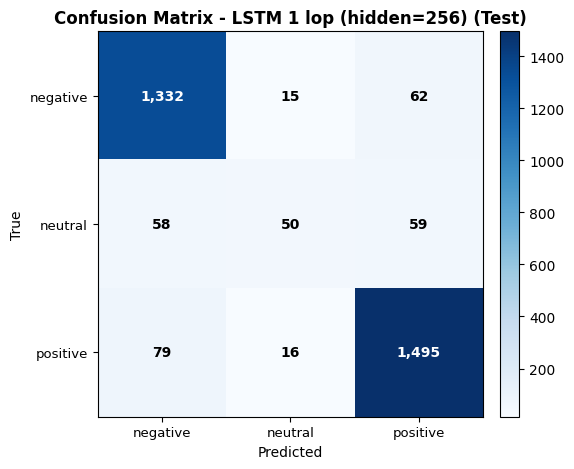

Bai 4b* - Huan luyen LSTM 2 lop (hidden=256)
epoch  1/10  train 0.3792/0.8667   dev 0.2838/0.9027  macro-F1 0.7360   (3.80s)  *
epoch  2/10  train 0.2438/0.9188   dev 0.2583/0.9185  macro-F1 0.7659   (3.44s)  *
epoch  3/10  train 0.1885/0.9402   dev 0.2593/0.9210  macro-F1 0.7762   (3.24s)  *
epoch  4/10  train 0.1418/0.9562   dev 0.2670/0.9255  macro-F1 0.7813   (3.27s)  *
epoch  5/10  train 0.1099/0.9662   dev 0.3134/0.9122  macro-F1 0.7638   (4.00s)
epoch  6/10  train 0.0743/0.9780   dev 0.3124/0.9217  macro-F1 0.7902   (3.34s)  *
epoch  7/10  train 0.0566/0.9821   dev 0.3393/0.9198  macro-F1 0.7823   (3.29s)
epoch  8/10  train 0.0401/0.9869   dev 0.4402/0.8926  macro-F1 0.7548   (3.64s)
epoch  9/10  train 0.0287/0.9912   dev 0.4451/0.9097  macro-F1 0.7827   (3.83s)
epoch 10/10  train 0.0215/0.9941   dev 0.4530/0.9172  macro-F1 0.7860   (3.41s)
-> best dev macro-F1: 0.7902 (epoch 6) | trung binh: 3.53s/epoch | da luu: outputs/bai4_lstm2/best.pt

KET QUA TAP TEST - LSTM 2 lop (hidden

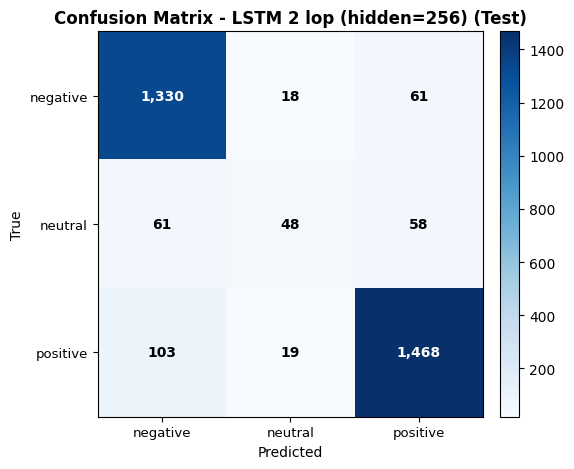

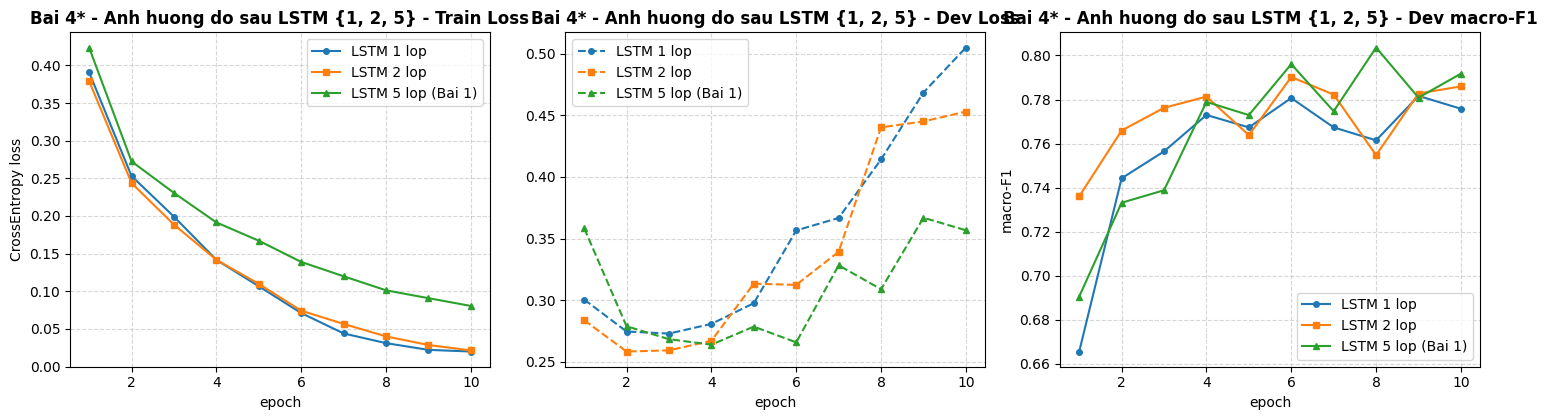

=== So sanh Bai 4*: Anh huong do sau LSTM num_layers = {1, 2, 5} (hidden=256) ===
Mo hinh                        |      Tham so | Best Ep |      s/ep |   Dev F1 | Test Acc |   Test P |   Test R |  Test F1
--------------------------------------------------------------------------------------------------------------------------
LSTM 1 lop (hidden=256)        |    1,032,663 |    9    |     2.46s |   0.7817 |   0.9087 |   0.8164 |   0.7283 |   0.7538
LSTM 2 lop (hidden=256)        |    1,558,999 |    6    |     3.53s |   0.7902 |   0.8989 |   0.7933 |   0.7182 |   0.7405
LSTM 5 lop (hidden=256)        |    3,138,007 |    8    |     6.10s |   0.8036 |   0.8999 |   0.7974 |   0.7522 |   0.7700



In [10]:
#Bai 4*: Huan luyen LSTM 1 lop va LSTM 2 lop, doi chieu cung LSTM 5 lop tu Bai 1
#1) LSTM 1 lop (hidden=256)
set_seed(SEED)
lstm_1 = TextClassifier(
    vocab_size=len(vocab), kind="LSTM", emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE, num_layers=1, dropout=DROPOUT,
)
print("Bai 4a* - Huan luyen LSTM 1 lop (hidden=256)")
hist_lstm1, info_lstm1 = fit_cls(
    model=lstm_1, train_dl=train_dl, dev_dl=dev_dl, epochs=EPOCHS, lr=LR,
    device=device, out_dir="outputs/bai4_lstm1", classes=SENTIMENT_LABELS,
    max_norm=CLIP_NORM, seed=SEED,
)
results["lstm_1"] = evaluate_cls_test(
    model=lstm_1, test_dl=test_dl, labels=SENTIMENT_LABELS, device=device,
    model_name="LSTM 1 lop (hidden=256)", summary=info_lstm1, out_dir="outputs/bai4_lstm1",
)

#2) LSTM 2 lop (hidden=256)
set_seed(SEED)
lstm_2 = TextClassifier(
    vocab_size=len(vocab), kind="LSTM", emb_dim=EMB_DIM,
    hidden_size=HIDDEN_SIZE, num_layers=2, dropout=DROPOUT,
)
print("Bai 4b* - Huan luyen LSTM 2 lop (hidden=256)")
hist_lstm2, info_lstm2 = fit_cls(
    model=lstm_2, train_dl=train_dl, dev_dl=dev_dl, epochs=EPOCHS, lr=LR,
    device=device, out_dir="outputs/bai4_lstm2", classes=SENTIMENT_LABELS,
    max_norm=CLIP_NORM, seed=SEED,
)
results["lstm_2"] = evaluate_cls_test(
    model=lstm_2, test_dl=test_dl, labels=SENTIMENT_LABELS, device=device,
    model_name="LSTM 2 lop (hidden=256)", summary=info_lstm2, out_dir="outputs/bai4_lstm2",
)

#Ve duong hoi tu va in bang so sanh num_layers = {1, 2, 5}
plot_cls_multi_curves(
    [("LSTM 1 lop", hist_lstm1), ("LSTM 2 lop", hist_lstm2), ("LSTM 5 lop (Bai 1)", hist_lstm5)],
    title="Bai 4* - Anh huong do sau LSTM {1, 2, 5}",
    save_path="outputs/bai4_depth_comparison.png",
)

depth_records = [results[k] for k in ("lstm_1", "lstm_2", "lstm_5") if k in results]
print_cls_comparison_table(
    depth_records,
    title="So sanh Bai 4*: Anh huong do sau LSTM num_layers = {1, 2, 5} (hidden=256)",
)

#### Nhận xét Bài 4\* (Phân biệt thay đổi kiến trúc và thay đổi số tham số)

- **Phân biệt hiệu ứng độ sâu kiến trúc và quy mô tham số:**
  - Khi tăng num_layers từ $1 \rightarrow 2 \rightarrow 5$, mỗi tầng LSTM cộng thêm **526.336 tham số** (nâng tổng tham số gấp 3 lần từ 1.03M lên 3.14M) và làm thời gian mỗi epoch tăng gần tuyến tính theo số tầng hồi quy tuần tự
  - Tuy nhiên, khác với cổng nhớ dọc theo trục thời gian $c_{t-1} \rightarrow c_t$, kết nối **theo chiều sâu giữa các tầng LSTM liên tiếp** ($h_t^{(l-1)} \rightarrow h_t^{(l)}$) trong nn.LSTM chuẩn **không có nhánh tắt cộng phần dư (residual skip connection)** và còn đi qua 4 lớp Dropout(0.3) nối tiếp ở cấu hình 5 lớp. Vì thế mạng 1–2 lớp thường hội tụ nhanh hơn ở những epoch đầu trên tập dữ liệu quy mô vừa (11.426 câu ngắn), trong khi mạng 5 lớp cần nhiều epoch hơn để tín hiệu gradient truyền hiệu quả xuống tầng Embedding và tầng LSTM đầu tiên
- **Lưu ý phương pháp luận:** Các số đo trên được ghi nhận với một hạt giống ngẫu nhiên cố định (SEED = 42) nhằm đảm bảo tính tái lập đối chứng; khoảng cách nhỏ vài phần nghìn macro-F1 giữa các cấu hình không nên được suy rộng thành kết luận tuyệt đối cho mọi tập dữ liệu nếu chưa lặp lại trên nhiều seed độc lập

---
### Tổng kết · Bảng tổng hợp kết quả cần nộp

Cell dưới đây tổng hợp tự động toàn bộ kết quả theo đúng biểu mẫu nộp bài của Lab 03:
1. **Bảng tổng hợp chuẩn cần nộp** (4 dòng bắt buộc: TF-IDF + Logistic Regression, LSTM 5 lớp, GRU 5 lớp, BiLSTM NER 5 lớp)
2. **Bảng chi tiết & biểu đồ toàn bộ các mô hình phân loại cảm xúc UIT-VSFC** (gồm cả Bài 4\*)

=== BANG TONG HOP KET QUA CAN NOP (LAB 03) ===
Mo hinh                        | Dev F1 tot nhat |   Test F1 | Do do F1              | Tham so / Cau hinh                     |   Giay/epoch
--------------------------------------------------------------------------------------------------------------------------------------------
TF-IDF + Logistic Regression   |          0.6894 |    0.6483 | Sentiment (macro-F1)  | TF-IDF(1-2g, 13,308 feat) + LogReg(39,927 w) |  3.48s (fit)
LSTM 5 lop (hidden=256)        |          0.8036 |    0.7700 | Sentiment (macro-F1)  | 3,138,007 tham so (ep 8)               |        6.10s
GRU 5 lop (hidden=256)         |          0.8014 |    0.7578 | Sentiment (macro-F1)  | 2,468,823 tham so (ep 8)               |        5.58s
BiLSTM NER 5 lop               |          0.9013 |    0.8947 | NER (Entity micro-F1) | 8,305,297 tham so (ep 10)              |        8.88s
Luu y: Macro-F1 o cac dong phan loai UIT-VSFC chi so sanh truc tiep voi nhau; Entity micro-F1 (strict

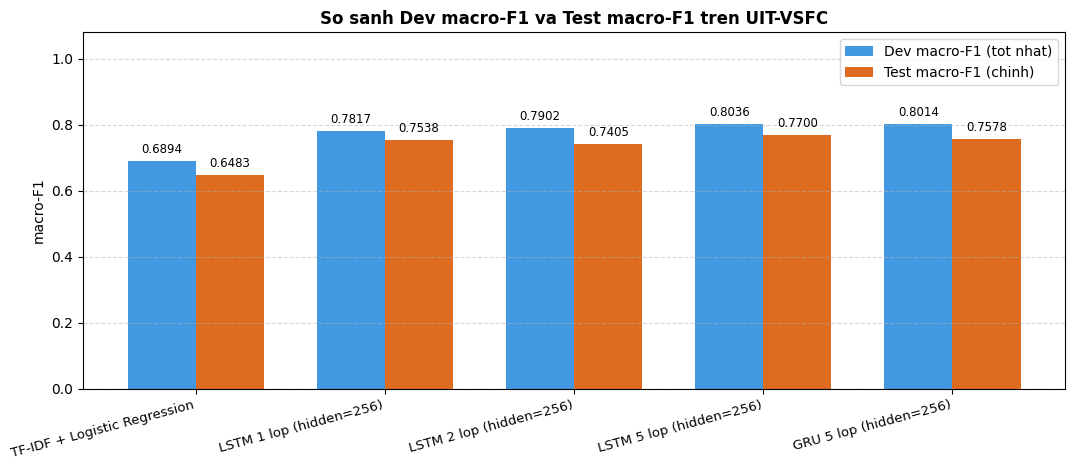

Da luu outputs/metadata_summary.json!


In [11]:
#1) Bang tong hop chuan can nop theo Lab 03
mandatory_order = ["tfidf", "lstm_5", "gru_5", "bilstm_ner"]
mandatory_records = [results[k] for k in mandatory_order if k in results]
if mandatory_records:
    print_final_submission_table(mandatory_records)

#2) Bang chi tiet toan bo cac mo hinh tren UIT-VSFC (Baseline + Bai 1 + Bai 2 + Bai 4*)
all_cls_order = ["tfidf", "lstm_1", "lstm_2", "lstm_5", "gru_5"]
all_cls_records = [results[k] for k in all_cls_order if k in results]
if all_cls_records:
    print_cls_comparison_table(
        all_cls_records,
        title="Bang tong hop toan bo thuc nghiem phan loai cam xuc UIT-VSFC",
    )
    plot_cls_model_comparison(all_cls_records, save_path="outputs/comparison_uit_vsfc.png")

#Luu metadata cau hinh & nguon du lieu phuc vu tai lap
Path("outputs").mkdir(parents=True, exist_ok=True)
summary_export = {
    "seed": SEED,
    "config": {
        "emb_dim": EMB_DIM,
        "hidden_size": HIDDEN_SIZE,
        "num_layers": NUM_LAYERS,
        "dropout": DROPOUT,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "clip_grad_norm": CLIP_NORM,
        "epochs": EPOCHS,
    },
    "data_sources": [{"path": p, "url": u, "sha256": h} for p, u, h in DATA_FILES],
    "results": {
        k: {rk: rv for rk, rv in v.items() if rk != "cm"}
        for k, v in results.items()
    },
}
Path("outputs/metadata_summary.json").write_text(
    json.dumps(summary_export, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("Da luu outputs/metadata_summary.json!")